# PHISHING HOSTNAME DETECTION WITH SVM
## Part 1 · Data profiling, auditing and cleaning (PhiUSIIL)

This notebook answers, in order: where the data comes from, what it contains, how clean
it is, which **traps** would make a model score artificially high, and what the final
data fed to the SVM looks like. Every number is recomputed from the raw CSV; nothing is
typed in by hand.

### Contents
1. Setup and data provenance
2. Overview: size, data types, column groups
3. Labels and class balance
4. Data quality checks
5. Finding 1 · URL format bias
6. Finding 2 · Leaking and out-of-scope features
7. Finding 3 · Shared hosting platforms
8. Cleaning: decisions and log
9. Profile of the cleaned data
10. Conclusions and implications for the SVM

## 1 · Setup and data provenance

- **Source:** [UCI PhiUSIIL Phishing URL Dataset](https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset), licence **CC BY 4.0**.
- **Original paper:** Prasad & Chandra (2024), *Computers & Security* 136, 103545.
- **Original label convention:** `1` = legitimate, `0` = phishing (per the UCI page). For
  modelling we flip it so that **phishing is the positive class**, since it is the class to detect.
- The file's SHA-256 is checked against the value recorded at download time, so it has not been altered.

In [1]:
import hashlib, json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data.py").exists())
sys.path.insert(0, str(ROOT))
from src.data import (RAW_CSV, class_balance, clean_hosts, hostname, is_bare_https_www,
                      load_raw, strip_www, univariate_auc)

FIG = ROOT / "outputs" / "eda"
FIG.mkdir(parents=True, exist_ok=True)
LEGIT, PHISH = "Legitimate", "Phishing"
COLORS = {LEGIT: "#2b6cb0", PHISH: "#c05621"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True})
pd.set_option("display.max_colwidth", 90)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")

meta = json.loads(RAW_CSV.with_suffix(".source.json").read_text(encoding="utf-8"))
sha_ok = hashlib.sha256(RAW_CSV.read_bytes()).hexdigest() == meta["csv_sha256"]
raw = load_raw()
raw["class"] = raw["label"].map({1: LEGIT, 0: PHISH})
pd.Series({
    "Downloaded at (UTC)": meta["downloaded_at_utc"][:19],
    "CSV size": f"{meta['csv_bytes'] / 1e6:.1f} MB",
    "SHA-256 matches record": sha_ok,
    "Rows": f"{len(raw):,}",
    "Columns (excluding helper column 'class')": raw.shape[1] - 1,
}).to_frame("Value")

,Value
Downloaded at (UTC),2026-10-27T04:14:53
CSV size,56.9 MB
SHA-256 matches record,True
Rows,"235,795"
Columns (excluding helper column 'class'),56


## 2 · Overview: what does the dataset contain?

Each row is **one URL** that the dataset authors visited and extracted features from. The
56 columns fall into 6 groups. Key point: most columns are **not** information about the
URL string but about the **page content** (HTML), which is only available after the page
has been opened.

In [2]:
URL_COLS = ["URLLength", "DomainLength", "IsDomainIP", "URLSimilarityIndex", "CharContinuationRate",
            "TLDLegitimateProb", "URLCharProb", "TLDLength", "NoOfSubDomain", "HasObfuscation",
            "NoOfObfuscatedChar", "ObfuscationRatio", "NoOfLettersInURL", "LetterRatioInURL",
            "NoOfDegitsInURL", "DegitRatioInURL", "NoOfEqualsInURL", "NoOfQMarkInURL",
            "NoOfAmpersandInURL", "NoOfOtherSpecialCharsInURL", "SpacialCharRatioInURL", "IsHTTPS"]
GROUPS = {
    "Identifier": ["FILENAME"],
    "Raw URL and components": ["URL", "Domain", "TLD"],
    "Precomputed URL features": URL_COLS,
    "Page-content (HTML) features": [],
    "Page text": ["Title"],
    "Label": ["label"],
}
known = {c for cols in GROUPS.values() for c in cols} | {"class"}
GROUPS["Page-content (HTML) features"] = [c for c in raw.columns if c not in known]
GROUP_OF = {c: g for g, cols in GROUPS.items() for c in cols}

overview = pd.DataFrame([
    {"Group": g, "Columns": len(cols),
     "Types": ", ".join(sorted(raw[cols].dtypes.astype(str).unique())),
     "Examples": ", ".join(cols[:4]) + (" …" if len(cols) > 4 else "")}
    for g, cols in GROUPS.items()
]).set_index("Group")
display(overview)
print(f"Total: {overview['Columns'].sum()} columns · in-memory size in pandas ≈ "
      f"{raw.memory_usage(deep=True).sum() / 1e6:.0f} MB")

,Columns,Types,Examples
Group,,,
Identifier,1,object,FILENAME
Raw URL and components,3,object,"URL, Domain, TLD"
Precomputed URL features,22,"float64, int64","URLLength, DomainLength, IsDomainIP, URLSimilarityIndex …"
Page-content (HTML) features,28,"float64, int64","LineOfCode, LargestLineLength, HasTitle, DomainTitleMatchScore …"
Page text,1,object,Title
Label,1,int64,label


Total: 56 columns · in-memory size in pandas ≈ 188 MB


### Full data dictionary

In [3]:
def describe(col):
    s = raw[col]
    row = {"Group": GROUP_OF[col], "Type": str(s.dtype), "Missing": int(s.isna().sum()),
           "Distinct values": s.nunique()}
    if pd.api.types.is_numeric_dtype(s):
        row["Min"], row["Max"] = s.min(), s.max()
        row["Example"] = "binary 0/1" if set(s.unique()) <= {0, 1} else f"median {s.median():g}"
    else:
        row["Min"] = row["Max"] = ""
        row["Example"] = str(s.iloc[0])[:45]
    return row

dictionary = pd.DataFrame({c: describe(c) for c in raw.columns if c != "class"}).T
dictionary.index.name = "Column"
dictionary

,Group,Type,Missing,Distinct values,Min,Max,Example
Column,,,,,,,
FILENAME,Identifier,object,0,235795,,,521848.txt
URL,Raw URL and components,object,0,235370,,,https://www.southbankmosaics.com
URLLength,Precomputed URL features,int64,0,482,13,6097,median 27
Domain,Raw URL and components,object,0,220086,,,www.southbankmosaics.com
DomainLength,Precomputed URL features,int64,0,101,4,110,median 20
IsDomainIP,Precomputed URL features,int64,0,2,0,1,binary 0/1
TLD,Raw URL and components,object,0,695,,,com
URLSimilarityIndex,Precomputed URL features,float64,0,36360,0.155574,100.0,median 100
CharContinuationRate,Precomputed URL features,float64,0,898,0.0,1.0,median 1


## 3 · Labels and class balance

,count,share
class,,
Legitimate,134850,0.5719
Phishing,100945,0.4281


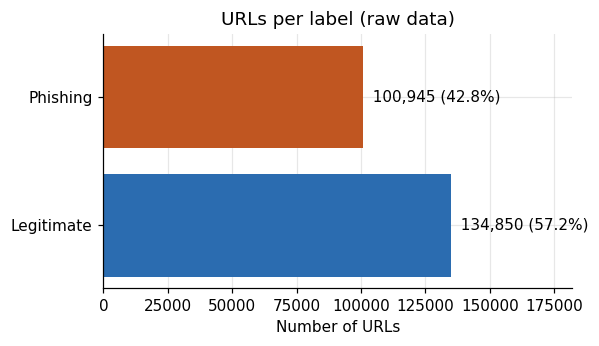

In [4]:
balance = class_balance(raw["class"])
display(balance)
fig, ax = plt.subplots(figsize=(5.5, 3))
ax.barh(balance.index, balance["count"], color=[COLORS[c] for c in balance.index])
for i, (n, s) in enumerate(zip(balance["count"], balance["share"])):
    ax.text(n, i, f"  {n:,} ({s:.1%})", va="center")
ax.set_xlim(0, balance["count"].max() * 1.35)
ax.set_title("URLs per label (raw data)")
ax.set_xlabel("Number of URLs")
save(fig, "01_label_balance"); plt.show()

The two classes are mildly imbalanced (about 57/43), so **no** oversampling is needed. When
subsampling for the SVM we use **stratified sampling** to keep the ratio, and we report
precision/recall in addition to accuracy.

## 4 · Data quality checks

Beyond counting missing cells, we check duplicates, label conflicts, and the
**consistency** between the columns and the URL string itself.

In [5]:
url = raw["URL"]
host = url.map(hostname)
dup_rows = url.duplicated(keep=False)
conflict_urls = raw[dup_rows].groupby("URL")["label"].nunique().gt(1).sum()
len_match = raw["URLLength"].eq(url.str.len())
checks = pd.DataFrame([
    ("Missing cells (whole table)", int(raw.isna().sum().sum()), "No imputation needed"),
    ("Rows with a duplicated URL", int(dup_rows.sum()), f"{url[dup_rows].nunique()} URLs appear twice → keep one"),
    ("Duplicated URLs with different labels", int(conflict_urls), "No label conflict at URL level"),
    ("Fully duplicated rows (ignoring FILENAME)", int(raw.drop(columns=["FILENAME", "class"]).duplicated().sum()), ""),
    ("URLLength = len(URL)", f"{len_match.mean():.1%}", "Precomputed column is off by one character → do not trust precomputed columns"),
    ("Domain column contains port ':' or '@'", int(raw["Domain"].str.contains("[:@]").sum()), "Original Domain keeps port/userinfo → re-parse ourselves"),
    ("URLs with uppercase letters", int(url.str.contains("[A-Z]").sum()), "All URLs were lowercased → no case-based features"),
    ("URLs with encoding errors (non-ASCII)", int((~url.map(str.isascii)).sum()), "Mojibake; the hostname is still valid"),
    ("Punycode hostnames (xn--)", int(host.str.contains("xn--").sum()), "Internationalised domains, often used for look-alike characters"),
    ("URLs whose hostname is an IP address", int(raw["IsDomainIP"].sum()), "100% in the phishing class"),
], columns=["Check", "Result", "Comment / action"]).set_index("Check")
checks

,Result,Comment / action
Check,,
Missing cells (whole table),0,No imputation needed
Rows with a duplicated URL,850,425 URLs appear twice → keep one
Duplicated URLs with different labels,0,No label conflict at URL level
Fully duplicated rows (ignoring FILENAME),0,
URLLength = len(URL),20.6%,Precomputed column is off by one character → do not trust precomputed columns
Domain column contains port ':' or '@',36,Original Domain keeps port/userinfo → re-parse ourselves
URLs with uppercase letters,0,All URLs were lowercased → no case-based features
URLs with encoding errors (non-ASCII),2,Mojibake; the hostname is still valid
Punycode hostnames (xn--),154,"Internationalised domains, often used for look-alike characters"


In [6]:
mismatch = (raw["URLLength"] - url.str.len()).rename("URLLength − len(URL)")
pd.crosstab(mismatch, raw["class"])

class,Legitimate,Phishing
URLLength − len(URL),,
-35,0,1
-4,0,1
-1,134850,52299
0,0,48644


**Comment.** The data is "clean" in the usual sense: no missing cells, very few duplicates,
no label conflicts. However, the `URLLength` column is **off by one character for 100% of
legitimate URLs** and only about half of the phishing URLs. In other words, a precomputed
column already carries a trace of the collection process rather than of phishing behaviour.
This is the first hint that something is wrong.

## 5 · Finding 1 · URL format bias

Question: do legitimate and phishing URLs share the **same format**?

class,Legitimate,Phishing
Uses https,100.0 %,48.7 %
Starts with www.,100.0 %,41.4 %
Has path / query,0.0 %,28.4 %
Ends with '/',0.0 %,36.5 %


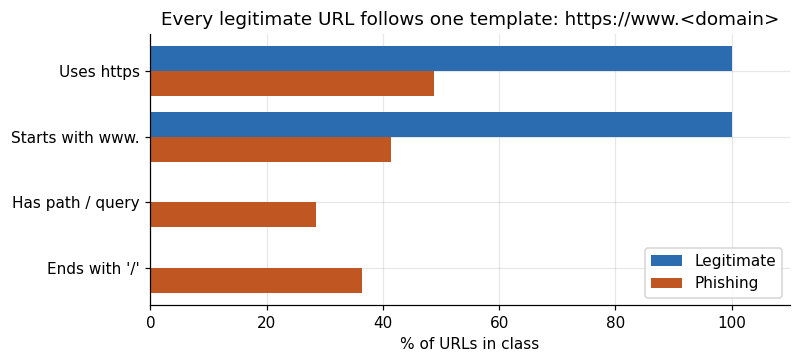

In [7]:
parts = url.str.extract(r"^(?P<scheme>[a-z]+)://(?P<www>www\.)?[^/?#]+(?P<rest>.*)$")
fmt = pd.DataFrame({
    "class": raw["class"],
    "Uses https": parts["scheme"].eq("https"),
    "Starts with www.": parts["www"].notna(),
    "Has path / query": parts["rest"].fillna("").str.strip("/").ne(""),
    "Ends with '/'": url.str.endswith("/"),
})
fmt_share = fmt.groupby("class").mean().T
display((fmt_share * 100).round(1).astype(str) + " %")

fig, ax = plt.subplots(figsize=(7.5, 3.2))
y = np.arange(len(fmt_share))
for k, cls in enumerate([LEGIT, PHISH]):
    ax.barh(y + (k - 0.5) * 0.38, fmt_share[cls] * 100, height=0.38, color=COLORS[cls], label=cls)
ax.set_yticks(y, fmt_share.index); ax.invert_yaxis()
ax.set_xlabel("% of URLs in class"); ax.set_xlim(0, 110); ax.legend(loc="lower right")
ax.set_title("Every legitimate URL follows one template: https://www.<domain>")
save(fig, "02_url_format_bias"); plt.show()

In [8]:
rule = url.map(is_bare_https_www)
display(pd.crosstab(rule.map({True: "Matches https://www.<host>", False: "Does not match"}), raw["class"]))
rule_acc = (rule == raw["label"].eq(1)).mean()
display(Markdown(f"**A single if–else rule, without any machine learning, reaches accuracy = {rule_acc:.2%}.**"))

class,Legitimate,Phishing
URL,,
Does not match,0,99906
Matches https://www.<host>,134850,1039


**A single if–else rule, without any machine learning, reaches accuracy = 99.56%.**

**Conclusion of Finding 1.** 100% of legitimate URLs are **bare homepages** of the form
`https://www.<domain>`: always https, always `www.`, never a path. This is an artefact of how
the authors **built the legitimate list** (popular domains prefixed with `https://www.`),
not a real property of legitimate web traffic. In the wild, legitimate URLs do have paths
(`/login`, `/account`, …).

Consequence: features extracted from the **whole URL string** (length, number of `/`,
https or not, keywords in the path, …) would let the SVM simply relearn the rule above and
reach ~99.6%, which is **meaningless**. The only information that **both classes genuinely
have** is the **hostname**.

## 6 · Finding 2 · Leaking and out-of-scope features

We measure the strength of **each precomputed column on its own** with ROC-AUC (0.5 = useless,
1.0 = perfect separation). A column close to 1.0 without a legitimate reason signals leakage.

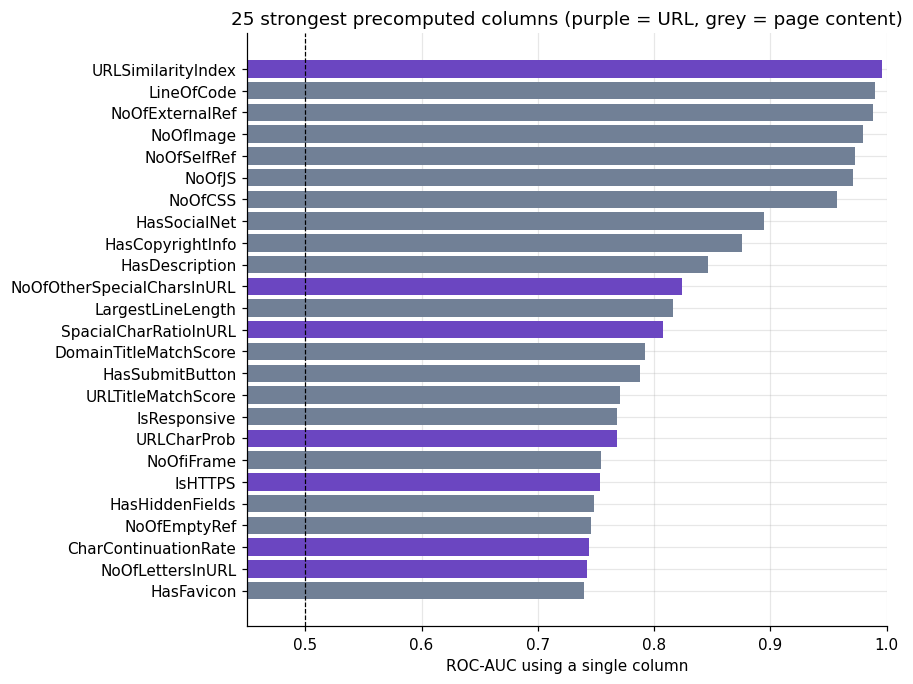

,AUC,Group
URLSimilarityIndex,0.9961,Precomputed URL features
LineOfCode,0.9903,Page-content (HTML) features
NoOfExternalRef,0.9880,Page-content (HTML) features
NoOfImage,0.9796,Page-content (HTML) features
NoOfSelfRef,0.9725,Page-content (HTML) features
NoOfJS,0.9708,Page-content (HTML) features
NoOfCSS,0.9576,Page-content (HTML) features
HasSocialNet,0.8947,Page-content (HTML) features
HasCopyrightInfo,0.8755,Page-content (HTML) features
HasDescription,0.8462,Page-content (HTML) features


In [9]:
numeric = raw.select_dtypes("number").drop(columns="label")
auc = univariate_auc(numeric, raw["label"]).rename("AUC").to_frame()
auc["Group"] = auc.index.map(GROUP_OF)
top = auc.head(25).iloc[::-1]
palette = {"Precomputed URL features": "#6b46c1", "Page-content (HTML) features": "#718096"}
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.barh(top.index, top["AUC"], color=top["Group"].map(palette))
ax.axvline(0.5, color="black", lw=0.8, ls="--")
ax.set_xlim(0.45, 1.0); ax.set_xlabel("ROC-AUC using a single column")
ax.set_title("25 strongest precomputed columns (purple = URL, grey = page content)")
save(fig, "03_univariate_auc"); plt.show()
auc.head(10).round(4)

**Conclusion of Finding 2.**

- `URLSimilarityIndex` alone reaches AUC ≈ 0.996. It measures how similar a URL is to the
  **legitimate URL list** the authors used to create the labels, i.e. it almost "peeks" at
  the label → **leakage**, removed.
- Page-content columns (`LineOfCode`, `NoOfExternalRef`, `NoOfImage`, …) are very strong but
  **require downloading the page**. Our task is detection from the address, before the user
  clicks, so these columns are **out of scope**.
- The remaining precomputed URL columns were computed on the biased URL string (Finding 1)
  and are off by one character (Section 4) → not used; we **extract our own features from
  the hostname**.

## 7 · Finding 3 · Shared hosting platforms

Many phishing URLs live on the **same platform** (Firebase, Replit, Weebly, IPFS, …). With a
random train/test split, the same platform would appear in both sets and the model would be
"given the answers".

In [10]:
hosts_raw = url.map(hostname).map(strip_www)
by_host = pd.DataFrame({"host": hosts_raw, "class": raw["class"]})
repeat = by_host.groupby("host").agg(n=("class", "size"), label=("class", "first")).sort_values("n", ascending=False)
display(repeat.head(10).rename(columns={"n": "URLs", "label": "Label"}))
print(f"{(repeat['n'] > 1).sum():,} hostnames have more than one URL; "
      f"largest: {repeat.index[0]} with {repeat['n'].iloc[0]:,} URLs")

,URLs,Label
host,,
ipfs.io,1197,Phishing
docs.google.com,526,Phishing
mail.deliverylifesupport.com,370,Phishing
cloudflare-ipfs.com,360,Phishing
storageapi.fleek.co,318,Phishing
gateway.pinata.cloud,275,Phishing
gateway.ipfs.io,249,Phishing
ipfs.litnet.work,223,Phishing
cf-ipfs.com,190,Phishing


5,875 hostnames have more than one URL; largest: ipfs.io with 1,197 URLs


The repeated hostnames are almost all **shared services** (`ipfs.io`, `docs.google.com`,
`bit.ly`) abused by attackers. After cleaning at hostname level, we look further at the
**registered domain** level (Section 9).

## 8 · Cleaning: decisions and log

| Issue | Decision | Reason |
|---|---|---|
| Legitimate URLs are all `https://www.<host>` | Keep only the **hostname**; drop scheme, `www.`, path | The hostname is the only real information both classes have |
| `URLSimilarityIndex` and the 28 page-content columns | Drop | Label leakage / out of scope |
| The other 21 precomputed URL columns | Drop, re-extract from the hostname | Computed on the biased string, off by one character |
| `FILENAME`, `Title` | Drop | Identifier / page-content text |
| Duplicated URLs | Keep one copy | Avoid double counting |
| Several URLs on the same hostname | Collapse into one row, keep `n_urls` | The unit of classification is the hostname |
| Hostname carrying both labels | Drop | Ambiguous, no single correct label |
| Userinfo `a@b`, port `:443` | Take the real hostname with `urlsplit` | The host the browser actually connects to |

,Rows remaining,Removed
Raw data (URLs),235795,0
Drop duplicated URLs,235370,425
Drop URLs without hostname,235370,0
Collapse to unique hostnames,219094,16276
Drop hostnames with conflicting labels,219036,58


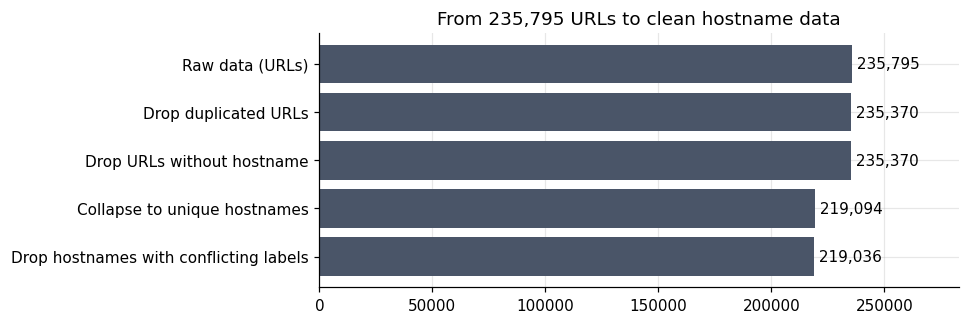

In [11]:
hosts, log = clean_hosts(raw)
log_df = pd.DataFrame(log).fillna(0).astype({"removed": int}).set_index("step")
log_df.index = ["Raw data (URLs)", "Drop duplicated URLs", "Drop URLs without hostname",
                "Collapse to unique hostnames", "Drop hostnames with conflicting labels"]
display(log_df.rename(columns={"rows": "Rows remaining", "removed": "Removed"}))

fig, ax = plt.subplots(figsize=(7.5, 3))
ax.barh(log_df.index[::-1], log_df["rows"][::-1], color="#4a5568")
for i, n in enumerate(log_df["rows"][::-1]):
    ax.text(n, i, f" {n:,}", va="center")
ax.set_xlim(0, log_df["rows"].max() * 1.2)
ax.set_title("From 235,795 URLs to clean hostname data")
save(fig, "04_cleaning_funnel"); plt.show()

In [12]:
schema = pd.DataFrame({
    "Meaning": ["Hostname with 'www.' removed (the model's only input)",
                "Registered domain (eTLD+1), used to group the train/test split",
                "Subdomain part in front of the registered domain",
                "Public suffix (com, co.uk, …) from the Public Suffix List",
                "1 if the hostname is an IP address",
                "Number of raw URLs collapsed into this hostname (analysis only, not a feature)",
                "Label: 1 = phishing, 0 = legitimate"],
    "Example": hosts.loc[hosts["subdomain"].ne("").idxmax()].astype(str).values,
}, index=hosts.columns)
schema

,Meaning,Example
host,Hostname with 'www.' removed (the model's only input),0-100pool.blocktrail.com
registered_domain,"Registered domain (eTLD+1), used to group the train/test split",blocktrail.com
subdomain,Subdomain part in front of the registered domain,0-100pool
suffix,"Public suffix (com, co.uk, …) from the Public Suffix List",com
is_ip,1 if the hostname is an IP address,0
n_urls,"Number of raw URLs collapsed into this hostname (analysis only, not a feature)",1
phishing,"Label: 1 = phishing, 0 = legitimate",1


## 9 · Profile of the cleaned data

In [13]:
hosts["class"] = hosts["phishing"].map({0: LEGIT, 1: PHISH})
display(class_balance(hosts["class"]))
reg = hosts.groupby("registered_domain").agg(n=("host", "size"), phishing=("phishing", "mean"))
pd.Series({
    "Hostnames": f"{len(hosts):,}",
    "Distinct registered domains": f"{len(reg):,}",
    "Registered domains with > 1 hostname": f"{(reg['n'] > 1).sum():,}",
    "Registered domains carrying both labels": f"{reg['phishing'].between(0, 1, inclusive='neither').sum():,}",
}).to_frame("Value")

,count,share
class,,
Legitimate,134792,0.6154
Phishing,84244,0.3846


,Value
Hostnames,"219,036"
Distinct registered domains,"175,452"
Registered domains with > 1 hostname,"2,977"
Registered domains carrying both labels,62


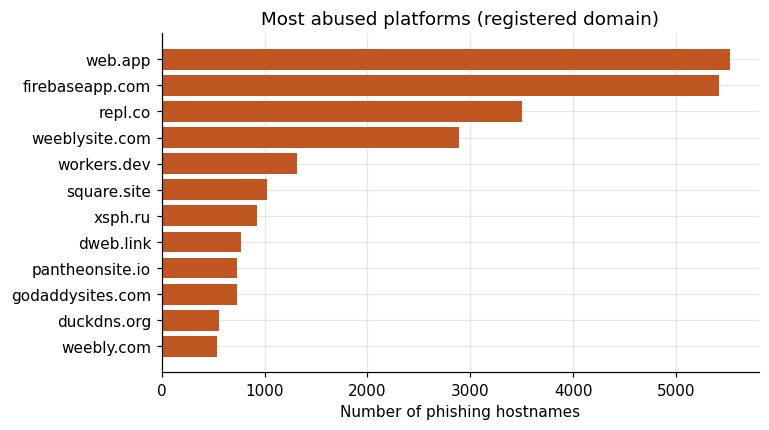

In [14]:
top_reg = reg.sort_values("n", ascending=False).head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top_reg.index, top_reg["n"], color=COLORS[PHISH])
ax.set_xlabel("Number of phishing hostnames")
ax.set_title("Most abused platforms (registered domain)")
save(fig, "05_top_platforms"); plt.show()

Thousands of phishing hostnames share one registered domain (`web.app`, `firebaseapp.com`,
`repl.co`, …). The train/test split is therefore **grouped by registered domain**
(`registered_domain` as the group): the model must recognise phishing on platforms it has
**never seen**, which is closer to real use.

### Hostname shape by class
The simple statistics below are descriptive only; they are not the final feature set.

class                   Legitimate  Phishing
Hostname length   mean       15.23     23.21
                  50%        15.00     20.00
                  max        46.00    110.00
Number of dots    mean        1.16      1.75
                  50%         1.00      2.00
                  max         4.00     11.00
Number of hyphens mean        0.08      0.57
                  50%         0.00      0.00
                  max         6.00     26.00
Number of digits  mean        0.05      2.05
                  50%         0.00      0.00
                  max         8.00     67.00

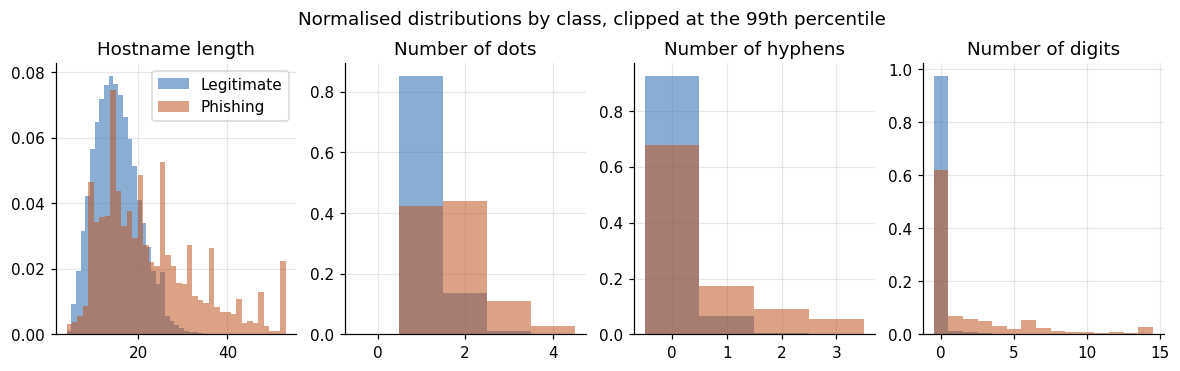

In [15]:
h = hosts["host"]
shape = pd.DataFrame({
    "class": hosts["class"],
    "Hostname length": h.str.len(),
    "Number of dots": h.str.count(r"\."),
    "Number of hyphens": h.str.count("-"),
    "Number of digits": h.str.count(r"\d"),
})
display(shape.groupby("class").describe().T.loc[(slice(None), ["mean", "50%", "max"]), :].round(2))

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, col in zip(axes, shape.columns[1:]):
    cap = shape[col].quantile(0.99)
    bins = np.arange(0, cap + 2) - 0.5 if cap < 30 else 40
    for cls in [LEGIT, PHISH]:
        ax.hist(shape.loc[shape["class"] == cls, col].clip(upper=cap), bins=bins, density=True,
                alpha=0.55, color=COLORS[cls], label=cls)
    ax.set_title(col)
axes[0].legend()
fig.suptitle("Normalised distributions by class, clipped at the 99th percentile", y=1.03)
save(fig, "06_host_shape"); plt.show()

In [16]:
sub_share = hosts.groupby("class")["subdomain"].apply(lambda s: s.ne("").mean())
ip_count = hosts.groupby("class")["is_ip"].sum()
display(pd.DataFrame({"Has subdomain": (sub_share * 100).round(1).astype(str) + " %",
                      "Is an IP address": ip_count}))

top_suffix = (hosts.groupby("class")["suffix"].value_counts(normalize=True)
              .groupby(level=0).head(8).mul(100).round(1).rename("% of class").reset_index())
display(top_suffix.pivot_table(index="suffix", columns="class", values="% of class").fillna(0)
        .sort_values(PHISH, ascending=False))

,Has subdomain,Is an IP address
class,,
Legitimate,2.9 %,0
Phishing,55.2 %,157


class,Legitimate,Phishing
suffix,,
com,51.0,44.3
app,0.0,7.2
co,0.0,4.9
net,3.0,3.3
ru,0.0,3.0
dev,0.0,2.5
org,12.3,2.5
top,0.0,2.3
co.uk,2.8,0.0


**Comments and caveats.**

- Phishing hostnames are **longer and contain more dots, hyphens and digits**, but the
  distributions **overlap heavily**. Each single statistic only reaches AUC ≈ 0.63–0.72, so
  the problem is **not trivial**; the SVM has real work to do.
- **Subdomain caveat:** the legitimate list consists of homepages of popular domains, so it
  has almost **no subdomains**, while more than half of the phishing hostnames do. Part of
  this difference is **real** (phishing often relies on subdomains of free platforms) and
  part is **a collection artefact** (in the wild, `mail.google.com` is legitimate). The
  experiments therefore include a variant **without subdomain features** to measure how much
  the model depends on them.
- The suffixes `.app`, `.dev`, `.io`, `.ru`, `.top` are much more common among phishing
  hostnames; `.org`, `.uk`, `.de` among legitimate ones. This too is influenced by how the
  legitimate list was built.

## 10 · Conclusions and implications for the SVM

In [17]:
n_hosts = len(hosts)
memory = pd.DataFrame({"n": [2_000, 3_000, 5_000, 10_000, n_hosts]})
memory["n×n kernel matrix (float64)"] = (memory["n"] ** 2 * 8 / 1e9).map(
    lambda gb: f"{gb * 1000:,.0f} MB" if gb < 1 else f"{gb:,.0f} GB")
display(memory.set_index("n"))

display(Markdown(f'''
**Analyst summary**

1. **Raw data:** {len(raw):,} URLs × 56 columns, no missing values, only {int(url.duplicated().sum())} duplicated URLs.
2. **Biggest trap:** every legitimate URL follows the template `https://www.<host>`; a single if–else rule reaches **{rule_acc:.2%}**.
   Hence only the **hostname** is used.
3. **Leakage:** `URLSimilarityIndex` (AUC {auc.loc["URLSimilarityIndex", "AUC"]:.3f}) and the 28 page-content columns are removed.
4. **Clean data:** {n_hosts:,} hostnames ({hosts["phishing"].sum():,} phishing,
   {(hosts["phishing"] == 0).sum():,} legitimate) from {hosts["registered_domain"].nunique():,} registered domains.
5. **For the SVM:** a kernel SVM cannot be trained on the full data (kernel matrix ~{n_hosts ** 2 * 8 / 1e9:,.0f} GB),
   so the from-scratch SMO uses a stratified subsample of 2,000–8,000 hostnames, while `LinearSVC` uses everything.
   The train/test split is **grouped by registered domain**, and feature scaling is fitted on the training set only.
6. **Next step:** extract hostname features (length, entropy, digits, hyphens, subdomain, suffix,
   brand/sensitive keywords) and run an extra variant without subdomain features.
'''))

,n×n kernel matrix (float64)
n,
2000,32 MB
3000,72 MB
5000,200 MB
10000,800 MB
219036,384 GB



**Analyst summary**

1. **Raw data:** 235,795 URLs × 56 columns, no missing values, only 425 duplicated URLs.
2. **Biggest trap:** every legitimate URL follows the template `https://www.<host>`; a single if–else rule reaches **99.56%**.
   Hence only the **hostname** is used.
3. **Leakage:** `URLSimilarityIndex` (AUC 0.996) and the 28 page-content columns are removed.
4. **Clean data:** 219,036 hostnames (84,244 phishing,
   134,792 legitimate) from 175,452 registered domains.
5. **For the SVM:** a kernel SVM cannot be trained on the full data (kernel matrix ~384 GB),
   so the from-scratch SMO uses a stratified subsample of 2,000–8,000 hostnames, while `LinearSVC` uses everything.
   The train/test split is **grouped by registered domain**, and feature scaling is fitted on the training set only.
6. **Next step:** extract hostname features (length, entropy, digits, hyphens, subdomain, suffix,
   brand/sensitive keywords) and run an extra variant without subdomain features.


### References
- Prasad, A., & Chandra, S. (2024). PhiUSIIL: A diverse security profile empowered phishing URL
  detection framework based on similarity index and incremental learning. *Computers & Security*,
  136, 103545. https://doi.org/10.1016/j.cose.2023.103545
- UCI Machine Learning Repository: PhiUSIIL Phishing URL Dataset (CC BY 4.0).
- Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining:
  Formulation, detection, and avoidance. *ACM TKDD*, 6(4).